# 中文预训练模型情感分类微调

本实验使用 UER 中文 RoBERTa-Medium 及其配套 WordPiece tokenizer，完成中文商品评论的正面、负面情感分类。

第1—5节提供环境检查、预训练文件下载和数据准备代码；第6—8节说明实验任务与提交结果；第9节提供本地模型的单句预测功能。

使用 VS Code 或 JupyterLab 运行。


## 1 环境与设备

本节显示 Python、PyTorch、Transformers 版本及计算设备，并检查设备计算。DEVICE="auto" 自动选择 CUDA、MPS 或 CPU。


In [1]:
from pathlib import Path
import sys, json, random
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import BertTokenizer
from IPython.display import display

print("解释器:", sys.executable)
print("Python:", sys.version)
print("PyTorch:", torch.__version__, "CUDA 构建:", torch.version.cuda)
print("Transformers:", transformers.__version__)
print("CUDA 可用:", torch.cuda.is_available())
print("MPS 可用:", torch.backends.mps.is_available())
DEVICE = "auto"  # 可改为 'cuda'、'mps'、'cpu'
if DEVICE == "auto":
    DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
if DEVICE == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA 不可用，请核对驱动与 PyTorch 构建")
if DEVICE == "mps" and not torch.backends.mps.is_available():
    raise RuntimeError("MPS 不可用，请核对 macOS、硬件与 PyTorch 支持")
device = torch.device(DEVICE)
x = torch.randn(64, 64, device=device)
assert torch.isfinite(x @ x).all().item()
del x
print("设备计算检查通过:", device)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


/home/biscuit/Documents/HIT-NLP/lab1/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


解释器: /home/biscuit/Documents/HIT-NLP/lab1/.venv/bin/python
Python: 3.11.14 (main, Dec  2 2025, 19:48:49) [Clang 21.1.4 ]
PyTorch: 2.5.1+cu124 CUDA 构建: 12.4
Transformers: 4.44.2
CUDA 可用: True
MPS 可用: False
设备计算检查通过: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 2 预训练文件与目录

模型：UER 中文 RoBERTa-Medium（uer/chinese_roberta_L-8_H-512）。编码：模型配套的 WordPiece tokenizer。

ROOT 为教学包目录。data 目录包含 train.csv、validation.csv 和 manifest.json。

本节自动下载模型配置、预训练权重及 tokenizer 文件，保存至 ROOT / "pretrained"。已有非空文件直接复用；首次下载需要联网。

MAX_LENGTH 为输入长度上限，BATCH_SIZE 和 EVAL_BATCH_SIZE 为数据分批参数。


In [2]:
ROOT = Path.cwd()  # 修改为教学包目录
DATA = ROOT / "data"
MODEL_ID = "uer/chinese_roberta_L-8_H-512"
SEED = 2024  # 训练随机种子（与报告微调最优单模型 len256_seed2024 一致）
MAX_LENGTH = 256  # 输入长度上限（256 仅截断约 0.7% 评论；128 会截断约 4.9%）
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
assert MAX_LENGTH >= 2 and BATCH_SIZE > 0 and EVAL_BATCH_SIZE > 0
assert DATA.is_dir(), "请将 ROOT 设置为教学包目录"
WP_DIR = ROOT / "pretrained"
from huggingface_hub import hf_hub_download


def prepare_file(repo, filename, directory):
    directory.mkdir(parents=True, exist_ok=True)
    target = directory / filename
    if not target.exists() or not target.stat().st_size:
        hf_hub_download(repo_id=repo, filename=filename, local_dir=str(directory))
    return target


for filename in [
    "config.json", "pytorch_model.bin",
    "vocab.txt", "tokenizer_config.json", "special_tokens_map.json",
]:
    print("准备文件:", filename, flush=True)
    prepare_file(MODEL_ID, filename, WP_DIR)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("预训练模型:", MODEL_ID, "；数据目录:", DATA)

print("预训练模型与 tokenizer 已就绪:", WP_DIR.resolve())


准备文件: config.json
准备文件: pytorch_model.bin
准备文件: vocab.txt
准备文件: tokenizer_config.json
准备文件: special_tokens_map.json
预训练模型: uer/chinese_roberta_L-8_H-512 ；数据目录: /home/biscuit/Documents/HIT-NLP/lab1/实验一情感分析教学包/data
预训练模型与 tokenizer 已就绪: /home/biscuit/Documents/HIT-NLP/lab1/实验一情感分析教学包/pretrained


## 3 训练集与验证集

数据为 MARC 中文评论正文。1—2星对应负面0，4—5星对应正面1，不使用3星样本。评分标签与文本情感可能存在差异。

训练集20,000条，正负各10,000条；验证集4,000条，正负各2,000条。CSV 包含 id、text、label。训练集用于训练，验证集用于验证与模型选择。

本节检查数据字段及样本记录，显示样本数量、类别分布和评论示例。


In [3]:
def read_split(name):
    assert name in {"train", "validation"}, "只允许读取训练集或验证集"
    frame = pd.read_csv(
        DATA / f"{name}.csv", keep_default_na=False, dtype={"id": str, "text": str}
    )
    assert {"id", "text", "label"}.issubset(frame.columns)
    assert len(frame) > 0 and frame["label"].isin([0, 1]).all()
    assert not frame["text"].str.strip().eq("").any()
    assert not frame["id"].eq("").any() and not frame["id"].duplicated().any()
    frame["label"] = frame["label"].astype(int)
    return frame


train_df = read_split("train")
dev_df = read_split("validation")
assert not set(train_df.id).intersection(dev_df.id)
for name, frame in [("train", train_df), ("validation", dev_df)]:
    print(name, len(frame), frame.label.value_counts().to_dict())
display(train_df.head())


train 20000 {1: 10000, 0: 10000}
validation 4000 {0: 2000, 1: 2000}


,id,text,label
0,zh_0826191,饭盒还算可以，但布袋质量差，还没用拉链就坏了。,1
1,zh_0978217,一天到晚吸毒、作画什么的，神经病似的的艺术家？！,0
2,zh_0245009,都是很基础的摄影，网上到处都看得见，编在书里毫无价值。不建议购买，！,0
3,zh_0615419,刚开始用的前几次，洗完头头发很顺；用到一半的时候就出问题了，每次冲洗护发素的时候能明显地感觉...,0
4,zh_0678062,拿到了吓一跳，椭圆形的，长直径刚好跟一元硬币一样。。。。。。。。。,1


## 4 WordPiece 文本编码

WordPiece 对文本进行基本切分后，匹配词表中的最长子词。## 标记接续片段，无法匹配时使用 [UNK]。词元编号对应 UER 配套词表。


### 4.1 tokenizer 与词元编号

本节加载 UER 配套 tokenizer，显示词表大小、文本切分及词元编号。


In [4]:
wp_tokenizer = BertTokenizer.from_pretrained(str(WP_DIR), local_files_only=True)
tokenizer = wp_tokenizer
print("模型:", MODEL_ID, "；编码: WordPiece；词表大小:", tokenizer.vocab_size)
for text in ["包装很好，但是商品质量差。", "这个keyboard很好用。", "unaffordable", "物流慢😡"]:
    tokens = tokenizer.tokenize(text)
    print("原文:", text)
    display(pd.DataFrame({"token": tokens, "id": tokenizer.convert_tokens_to_ids(tokens)}))


模型: uer/chinese_roberta_L-8_H-512 ；编码: WordPiece；词表大小: 21128
原文: 包装很好，但是商品质量差。


/home/biscuit/Documents/HIT-NLP/lab1/.venv/lib/python3.11/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


,token,id
0,包,1259
1,装,6163
2,很,2523
3,好,1962
4,，,8024
5,但,852
6,是,3221
7,商,1555
8,品,1501
9,质,6574


原文: 这个keyboard很好用。


,token,id
0,这,6821
1,个,702
2,key,9232
3,##board,9472
4,很,2523
5,好,1962
6,用,4500
7,。,511


原文: unaffordable


,token,id
0,u,163
1,##na,8374
2,##ff,9049
3,##or,8372
4,##da,8521
5,##ble,8862


原文: 物流慢😡


,token,id
0,物,4289
1,流,3837
2,慢,2714
3,[UNK],100


### 4.2 最长匹配过程

本节展示 WordPiece 的候选匹配过程。中文汉字在基本切分阶段分开，再分别查词表。


In [5]:
WORDPIECE_TEXT = "keyboard"
basic_segments = wp_tokenizer.basic_tokenizer.tokenize(WORDPIECE_TEXT)
vocabulary = wp_tokenizer.wordpiece_tokenizer.vocab
trace = []
result_tokens = []
for segment in basic_segments:
    start = 0
    segment_tokens = []
    failed = len(segment) > wp_tokenizer.wordpiece_tokenizer.max_input_chars_per_word
    while start < len(segment) and not failed:
        tried = []
        chosen = None
        for end in range(len(segment), start, -1):
            candidate = segment[start:end]
            if start > 0:
                candidate = "##" + candidate
            tried.append(candidate)
            if candidate in vocabulary:
                chosen = candidate
                break
        trace.append(
            {
                "基本片段": segment,
                "起始位置": start,
                "依次尝试的候选": " → ".join(tried),
                "采用词元": chosen if chosen is not None else "[UNK]",
                "词表编号": (
                    vocabulary[chosen]
                    if chosen is not None
                    else wp_tokenizer.unk_token_id
                ),
            }
        )
        if chosen is None:
            failed = True
        else:
            segment_tokens.append(chosen)
            start = end
    # 任一部分无法匹配时，整个基本片段使用[UNK]，与原实现一致。
    result_tokens.extend([wp_tokenizer.unk_token] if failed else segment_tokens)

actual_tokens = wp_tokenizer.tokenize(WORDPIECE_TEXT)
assert result_tokens == actual_tokens
print("原文：", WORDPIECE_TEXT)
print("基本切分：", basic_segments)
display(pd.DataFrame(trace))
print("最终词元：", actual_tokens)
print("真实编号：", wp_tokenizer.convert_tokens_to_ids(actual_tokens))
print("重复执行一致：", actual_tokens == wp_tokenizer.tokenize(WORDPIECE_TEXT))


原文： keyboard
基本切分： ['keyboard']


,基本片段,起始位置,依次尝试的候选,采用词元,词表编号
0,keyboard,0,keyboard → keyboar → keyboa → keybo → keyb → key,key,9232
1,keyboard,3,##board,##board,9472


最终词元： ['key', '##board']
真实编号： [9232, 9472]
重复执行一致： True


### 4.3 模型输入

[CLS] 和 [SEP] 为特殊标记。attention_mask 中 1 表示有效位置，0 表示补齐位置；token_type_ids 标识句子片段。

encode_inputs 将评论转换为模型输入。本节示例长度上限为16，包含特殊标记；第5节使用 MAX_LENGTH。


In [6]:
def encode_inputs(texts, max_length):
    return tokenizer(
        list(texts), truncation=True, max_length=max_length,
        padding=True, return_tensors="pt",
    )

examples = ["质量很好。", "包装很好，但是商品质量很差，使用一天就坏了。"]
example_inputs = encode_inputs(examples, 16)
print("模型:", MODEL_ID, "；tokenizer:", type(tokenizer).__name__)
for i, text in enumerate(examples):
    print(text)
    display(pd.DataFrame({
        "token": tokenizer.convert_ids_to_tokens(example_inputs["input_ids"][i].tolist()),
        "input_id": example_inputs["input_ids"][i].tolist(),
        "attention_mask": example_inputs["attention_mask"][i].tolist(),
        "token_type_id": example_inputs["token_type_ids"][i].tolist(),
    }))


模型: uer/chinese_roberta_L-8_H-512 ；tokenizer: BertTokenizer
质量很好。


,token,input_id,attention_mask,token_type_id
0,[CLS],101,1,0
1,质,6574,1,0
2,量,7030,1,0
3,很,2523,1,0
4,好,1962,1,0
5,。,511,1,0
6,[SEP],102,1,0
7,[PAD],0,0,0
8,[PAD],0,0,0
9,[PAD],0,0,0


包装很好，但是商品质量很差，使用一天就坏了。


,token,input_id,attention_mask,token_type_id
0,[CLS],101,1,0
1,包,1259,1,0
2,装,6163,1,0
3,很,2523,1,0
4,好,1962,1,0
5,，,8024,1,0
6,但,852,1,0
7,是,3221,1,0
8,商,1555,1,0
9,品,1501,1,0


## 5 Dataset 与 DataLoader

Dataset 提供评论和标签，DataLoader 通过 encode_inputs 组织批次。动态 padding 将同批评论补齐至相同长度。

- input_ids、attention_mask、token_type_ids：批次大小 × 当前批次长度。
- labels：批次大小，标签为0或1。

本节创建训练集和验证集的数据接口，并显示输入形状与数据类型。


In [7]:
print("【训练输入】模型:", MODEL_ID, "；tokenizer:", type(tokenizer).__name__)


class Reviews(torch.utils.data.Dataset):
    def __init__(self, frame):
        self.texts = frame.text.tolist()
        self.labels = frame.label.tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.texts[index], self.labels[index]


def collate(rows):
    texts, labels = zip(*rows)
    inputs = encode_inputs(texts, MAX_LENGTH)
    inputs["labels"] = torch.tensor(labels, dtype=torch.long)
    return inputs


train_loader = torch.utils.data.DataLoader(
    Reviews(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate,
    num_workers=0,
)
dev_loader = torch.utils.data.DataLoader(
    Reviews(dev_df),
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=collate,
    num_workers=0,
)
print("训练 batch 数:", len(train_loader), "验证 batch 数:", len(dev_loader))
example_batch = next(iter(dev_loader))
for key, value in example_batch.items():
    print(key, tuple(value.shape), value.dtype)


【训练输入】模型: uer/chinese_roberta_L-8_H-512 ；tokenizer: BertTokenizer
训练 batch 数: 625 验证 batch 数: 63
input_ids (64, 189) torch.int64
token_type_ids (64, 189) torch.int64
attention_mask (64, 189) torch.int64
labels (64,) torch.int64


## 6 情感分类微调

使用已准备的 UER 预训练模型和评论数据，完成情感分类微调。模型输出对应负面0、正面1两类。

实验结果包括所用方法与配置、训练记录、验证指标及保存的模型。


In [8]:
# 加载 UER 预训练模型并接上二分类头，随后准备优化器与学习率调度。
# UER 权重不含 pooler（预训练无 NSP），pooler 与分类头为随机初始化，
# 微调时与全部主体参数一起更新（全参数微调）。
import time
from transformers import BertForSequenceClassification, get_linear_schedule_with_warmup

LEARNING_RATE = 2e-5   # 微调学习率
EPOCHS = 3             # 训练轮数
WARMUP_RATIO = 0.1     # 前 10% 步线性预热，其余线性衰减到 0
WEIGHT_DECAY = 0.01    # 仅作用于权重矩阵（偏置与 LayerNorm 不施正则）
GRAD_CLIP = 1.0        # 梯度裁剪阈值

# 固定随机种子：模型初始化（pooler/分类头）、批打乱与 dropout 均由它决定
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

model = BertForSequenceClassification.from_pretrained(
    str(WP_DIR), num_labels=2, local_files_only=True)
model.config.id2label = {0: "负面", 1: "正面"}
model.config.label2id = {"负面": 0, "正面": 1}
model.config.pad_token_id = tokenizer.pad_token_id
model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"参数量：总 {total_params:,}，可训练 {trainable_params:,}"
      f"（{trainable_params / total_params:.2%}）")

# AdamW 参数分组：偏置与 LayerNorm 权重不施加 weight decay（BERT 微调常规做法）
no_decay = ("bias", "LayerNorm.weight")
param_groups = [
    {"params": [p for n, p in model.named_parameters()
                if not any(nd in n for nd in no_decay)],
     "weight_decay": WEIGHT_DECAY},
    {"params": [p for n, p in model.named_parameters()
                if any(nd in n for nd in no_decay)],
     "weight_decay": 0.0},
]
optimizer = torch.optim.AdamW(param_groups, lr=LEARNING_RATE)

# 线性预热-衰减调度：总步数 = 每轮批数 × 轮数
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(total_steps * WARMUP_RATIO),
    num_training_steps=total_steps)
print(f"训练步数：{total_steps}（{len(train_loader)} 步/轮 × {EPOCHS} 轮）")


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at /home/biscuit/Documents/HIT-NLP/lab1/实验一情感分析教学包/pretrained and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


参数量：总 36,564,482，可训练 36,564,482（100.00%）
训练步数：1875（625 步/轮 × 3 轮）


In [9]:
# 训练与评价函数：训练 = 前向 → 反向 → 梯度裁剪 → 参数更新 → 学习率调度。
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score


def train_one_epoch(m, loader, log_every=100):
    m.train()
    losses = []
    for step, batch in enumerate(loader, start=1):
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = m(**batch)          # 模型内部按交叉熵计算 loss（logits 与 labels）
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()
        losses.append(loss.item())
        if step % log_every == 0:
            print(f"  step {step}/{len(loader)}"
                  f"  loss={np.mean(losses[-log_every:]):.4f}"
                  f"  lr={scheduler.get_last_lr()[0]:.2e}", flush=True)
    return losses


@torch.inference_mode()
def evaluate(m, loader):
    # 返回（平均验证 loss、正面概率、预测、标签）；预测为 logits 的 argmax
    m.eval()
    losses, scores, preds, labels = [], [], [], []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = m(**batch)
        losses.append(outputs.loss.item())
        probs = outputs.logits.softmax(dim=-1).cpu()
        scores.append(probs[:, 1].numpy())
        preds.append(probs.argmax(dim=-1).numpy())
        labels.append(batch["labels"].cpu().numpy())
    return (float(np.mean(losses)), np.concatenate(scores),
            np.concatenate(preds), np.concatenate(labels))


def compute_metrics(labels, preds):
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
        "precision_macro": precision_score(labels, preds, average="macro"),
        "recall_macro": recall_score(labels, preds, average="macro"),
    }

print("训练与评价函数已就绪")


训练与评价函数已就绪


In [10]:
# 训练主循环：每轮训练后在验证集评价；按验证集 Macro-F1 保存最优模型。
SAVE_DIR = ROOT / "finetuned"     # 模型与实验记录的保存目录
SAVE_DIR.mkdir(parents=True, exist_ok=True)

step_records = []                 # 每步 loss（曲线素材）
epoch_records = []                # 每轮指标（训练记录）
best = {"macro_f1": -1.0}         # 当前验证集最优

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    print(f"--- 轮次 {epoch}/{EPOCHS} ---")
    losses = train_one_epoch(model, train_loader)
    base_step = len(step_records)
    step_records += [{"step": base_step + i, "loss": round(loss, 5)}
                     for i, loss in enumerate(losses, start=1)]

    val_loss, scores, preds, labels = evaluate(model, dev_loader)
    metrics = compute_metrics(labels, preds)
    record = {"epoch": epoch, "train_loss": round(float(np.mean(losses)), 4),
              "val_loss": round(val_loss, 4),
              **{k: round(v, 4) for k, v in metrics.items()},
              "epoch_time_sec": round(time.time() - t0, 1)}
    epoch_records.append(record)
    print(f"轮次 {epoch}: train_loss={record['train_loss']:.4f}"
          f"  val_loss={record['val_loss']:.4f}"
          f"  val_acc={record['accuracy']:.4f}"
          f"  val_macroF1={record['macro_f1']:.4f}"
          f"（{record['epoch_time_sec']}s）")

    if metrics["macro_f1"] > best["macro_f1"]:
        best = {"macro_f1": metrics["macro_f1"], "epoch": epoch,
                "metrics": metrics, "val_loss": val_loss,
                "scores": scores, "preds": preds, "labels": labels}
        model.save_pretrained(SAVE_DIR, safe_serialization=True)
        tokenizer.save_pretrained(SAVE_DIR)
        print(f"  ↑ 新的最优模型（epoch {epoch}，"
              f"Macro-F1={metrics['macro_f1']:.4f}）已保存到 {SAVE_DIR}")

print(f"\n训练完成：最优第 {best['epoch']} 轮，验证集 Macro-F1={best['macro_f1']:.4f}")


--- 轮次 1/3 ---
  step 100/625  loss=0.5751  lr=1.07e-05
  step 200/625  loss=0.3698  lr=1.98e-05
  step 300/625  loss=0.3549  lr=1.87e-05
  step 400/625  loss=0.3305  lr=1.75e-05
  step 500/625  loss=0.3221  lr=1.63e-05
  step 600/625  loss=0.3363  lr=1.51e-05
轮次 1: train_loss=0.3794  val_loss=0.3546  val_acc=0.8668  val_macroF1=0.8666（124.2s）
  ↑ 新的最优模型（epoch 1，Macro-F1=0.8666）已保存到 /home/biscuit/Documents/HIT-NLP/lab1/实验一情感分析教学包/finetuned
--- 轮次 2/3 ---
  step 100/625  loss=0.2940  lr=1.36e-05
  step 200/625  loss=0.2866  lr=1.24e-05
  step 300/625  loss=0.2793  lr=1.13e-05
  step 400/625  loss=0.2900  lr=1.01e-05
  step 500/625  loss=0.2825  lr=8.89e-06
  step 600/625  loss=0.2801  lr=7.70e-06
轮次 2: train_loss=0.2853  val_loss=0.3284  val_acc=0.8788  val_macroF1=0.8787（125.1s）
  ↑ 新的最优模型（epoch 2，Macro-F1=0.8787）已保存到 /home/biscuit/Documents/HIT-NLP/lab1/实验一情感分析教学包/finetuned
--- 轮次 3/3 ---
  step 100/625  loss=0.2347  lr=6.22e-06
  step 200/625  loss=0.2433  lr=5.04e-06
  step 300/625 

## 7 模型验证与保存

每轮评价验证集，保存验证集 Macro-F1 最高的模型，记录训练 loss 与验证结果。

加载保存的模型，核对验证成绩，报告 Accuracy、Macro-F1、Precision 和 Recall。


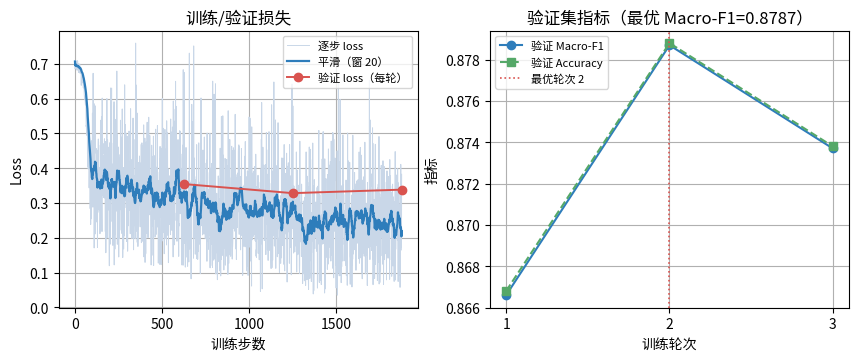

,epoch,train_loss,val_loss,accuracy,macro_f1,precision_macro,recall_macro,epoch_time_sec
0,1,0.3794,0.3546,0.8668,0.8666,0.8681,0.8668,124.2
1,2,0.2853,0.3284,0.8788,0.8787,0.8788,0.8788,125.1
2,3,0.2451,0.3385,0.8738,0.8737,0.8739,0.8738,126.6


In [11]:
# 训练曲线：每步 loss（滑动平均）与逐轮验证指标；下方为逐轮训练记录表。
import matplotlib.pyplot as plt
from matplotlib import font_manager

installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
for font_name in ["Noto Sans CJK SC", "Noto Sans CJK JP", "WenQuanYi Zen Hei",
                  "SimHei", "Microsoft YaHei"]:
    if font_name in installed_fonts:
        plt.rcParams["font.sans-serif"] = [font_name]
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.grid"] = True

steps_df = pd.DataFrame(step_records)
epochs_df = pd.DataFrame(epoch_records)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.6))
smooth = steps_df["loss"].rolling(20, min_periods=1).mean()
axes[0].plot(steps_df["step"], steps_df["loss"], color="#c9d7e8", lw=0.7,
             label="逐步 loss")
axes[0].plot(steps_df["step"], smooth, color="#2e7dbb", lw=1.6,
             label="平滑（窗 20）")
epoch_steps = [len(train_loader) * e for e in range(1, EPOCHS + 1)]
axes[0].plot(epoch_steps, epochs_df["val_loss"], "o-", color="#d9534f", lw=1.4,
             label="验证 loss（每轮）")
axes[0].set_xlabel("训练步数")
axes[0].set_ylabel("Loss")
axes[0].set_title("训练/验证损失")
axes[0].legend(fontsize=8)

axes[1].plot(epochs_df["epoch"], epochs_df["macro_f1"], "o-", color="#2e7dbb",
             label="验证 Macro-F1")
axes[1].plot(epochs_df["epoch"], epochs_df["accuracy"], "s--", color="#55a868",
             label="验证 Accuracy")
axes[1].axvline(best["epoch"], color="#d9534f", ls=":", lw=1.2,
                label=f"最优轮次 {best['epoch']}")
axes[1].set_xlabel("训练轮次")
axes[1].set_ylabel("指标")
axes[1].set_xticks(epochs_df["epoch"])
axes[1].set_title(f"验证集指标（最优 Macro-F1={best['macro_f1']:.4f}）")
axes[1].legend(fontsize=8)
fig.savefig(SAVE_DIR / "training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

# 逐轮训练记录
display(epochs_df)


In [12]:
# 从保存目录恢复最优模型并重新评价验证集，核对成绩（与第 9 节相同的完整恢复流程）。
from transformers import BertConfig
from sklearn.metrics import confusion_matrix

restored_config = BertConfig.from_pretrained(str(SAVE_DIR), local_files_only=True)
assert restored_config.num_labels == 2, "需要二分类模型"
restored_tokenizer = BertTokenizer.from_pretrained(str(SAVE_DIR), local_files_only=True)
restored_model, loading_info = BertForSequenceClassification.from_pretrained(
    str(SAVE_DIR), local_files_only=True, output_loading_info=True)
assert not loading_info.get("missing_keys"), loading_info
assert not loading_info.get("mismatched_keys"), loading_info
assert restored_model.config.pad_token_id == restored_tokenizer.pad_token_id, \
    "模型与 tokenizer 的 pad_token_id 不一致"
restored_model = restored_model.to(device).eval()

restored_val_loss, restored_scores, restored_preds, restored_labels = evaluate(
    restored_model, dev_loader)
restored_metrics = compute_metrics(restored_labels, restored_preds)
print("恢复模型验证集：", {k: round(v, 4) for k, v in restored_metrics.items()})
print("与训练记录核对（最优轮次）：",
      {k: ("一致" if abs(restored_metrics[k] - best["metrics"][k]) < 1e-6 else "不一致")
       for k in restored_metrics})

# 混淆矩阵（行=真实，列=预测）
cm = confusion_matrix(restored_labels, restored_preds, labels=[0, 1])
display(pd.DataFrame(cm, index=["真实负面", "真实正面"], columns=["预测负面", "预测正面"]))


恢复模型验证集： {'accuracy': 0.8788, 'macro_f1': 0.8787, 'precision_macro': 0.8788, 'recall_macro': 0.8788}
与训练记录核对（最优轮次）： {'accuracy': '一致', 'macro_f1': '一致', 'precision_macro': '一致', 'recall_macro': '一致'}


,预测负面,预测正面
真实负面,1761,239
真实正面,246,1754


## 8 实验结果

保存实验相关文件与结果，在报告中说明所用方法、实际配置、评价结果及分析。具体提交要求见实验指导书。


In [13]:
# 保存实验结果：逐轮指标、每步 loss、最优轮次验证集预测与训练记录（供报告引用）。
epochs_df.to_csv(SAVE_DIR / "epoch_metrics.csv", index=False, encoding="utf-8-sig")
steps_df.to_csv(SAVE_DIR / "steps.csv", index=False)

# 验证集预测使用“最优轮次”的结果（而非最后一轮）
pd.DataFrame({
    "id": dev_df["id"], "text": dev_df["text"], "label": best["labels"],
    "pred": best["preds"], "score_positive": best["scores"],
    "correct": (best["preds"] == best["labels"]).astype(int),
}).to_csv(SAVE_DIR / "dev_predictions.csv", index=False, encoding="utf-8-sig")

train_log = {
    "model": MODEL_ID, "max_length": MAX_LENGTH, "batch_size": BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE, "epochs": EPOCHS, "seed": SEED,
    "learning_rate": LEARNING_RATE, "warmup_ratio": WARMUP_RATIO,
    "weight_decay": WEIGHT_DECAY,
    "total_params": total_params, "trainable_params": trainable_params,
    "total_steps": total_steps,
    "epoch_records": epoch_records,
    "best": {"epoch": best["epoch"], "val_loss": best["val_loss"],
             "metrics": best["metrics"], "macro_f1": best["macro_f1"]},
    "model_dir": str(SAVE_DIR),
}
(SAVE_DIR / "train_log.json").write_text(
    json.dumps(train_log, ensure_ascii=False, indent=2), encoding="utf-8")

summary = pd.DataFrame([{
    "模型": MODEL_ID, "输入长度": MAX_LENGTH, "批大小": BATCH_SIZE, "轮数": EPOCHS,
    "训练种子": SEED, "最优轮次": best["epoch"],
    "Accuracy": round(best["metrics"]["accuracy"], 4),
    "Macro-F1": round(best["metrics"]["macro_f1"], 4),
    "Precision": round(best["metrics"]["precision_macro"], 4),
    "Recall": round(best["metrics"]["recall_macro"], 4),
}])
display(summary)
print(f"实验记录与验证集预测已保存到 {SAVE_DIR}")


,模型,输入长度,批大小,轮数,训练种子,最优轮次,Accuracy,Macro-F1,Precision,Recall
0,uer/chinese_roberta_L-8_H-512,256,32,3,2024,2,0.8788,0.8787,0.8788,0.8788


实验记录与验证集预测已保存到 /home/biscuit/Documents/HIT-NLP/lab1/实验一情感分析教学包/finetuned


## 9 本地模型与单句预测

本节可单独运行。LOCAL_MODEL_DIR 指向包含完整 UER 二分类模型与配套 WordPiece tokenizer 的本地目录。INFERENCE_MAX_LENGTH 与该模型微调时的输入长度一致，INFERENCE_LABELS 与训练标签一致。

第一个代码块加载模型，第二个代码块对 sentences 中的评论进行预测。


In [14]:
from pathlib import Path
import gc
import torch
import pandas as pd
from IPython.display import display
from transformers import BertConfig, BertTokenizer, BertForSequenceClassification

LOCAL_MODEL_DIR = Path.cwd() / "finetuned"  # 第6—8节训练保存的完整模型目录（可修改为其他本地完整模型）
INFERENCE_MAX_LENGTH = 256  # 与该模型微调时使用的输入长度一致（本实验为 256）
INFERENCE_LABELS = {0: "负面", 1: "正面"}  # 与该模型训练标签一致
INFERENCE_DEVICE = "auto"  # 'cuda'、'mps'、'cpu'
LOCAL_MODEL_READY = False
# 切换目录时释放前一次加载的模型。
globals().pop("local_model", None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
LOCAL_MODEL_DIR = LOCAL_MODEL_DIR.expanduser().resolve()
if not LOCAL_MODEL_DIR.is_dir():
    raise FileNotFoundError(f"请设置已有的本地完整模型目录：{LOCAL_MODEL_DIR}")
if INFERENCE_DEVICE == "auto":
    INFERENCE_DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
inference_device = torch.device(INFERENCE_DEVICE)
local_config = BertConfig.from_pretrained(str(LOCAL_MODEL_DIR), local_files_only=True)
if local_config.num_labels != 2:
    raise ValueError("本示例需要二分类模型，请检查模型配置与任务标签")
local_tokenizer = BertTokenizer.from_pretrained(str(LOCAL_MODEL_DIR), local_files_only=True)
local_model, loading_info = BertForSequenceClassification.from_pretrained(
    str(LOCAL_MODEL_DIR), local_files_only=True, output_loading_info=True
)
if loading_info.get("missing_keys") or loading_info.get("mismatched_keys"):
    del local_model
    raise ValueError("模型权重缺失或尺寸不匹配，请导出完整的已微调分类模型")
if local_tokenizer.pad_token_id is None:
    raise ValueError("tokenizer 缺少 pad_token，请恢复微调时的 tokenizer 配置")
if local_model.config.pad_token_id != local_tokenizer.pad_token_id:
    raise ValueError("模型与 tokenizer 的 pad_token_id 不一致，请检查保存配置")
local_model = local_model.to(inference_device).eval()
LOCAL_MODEL_READY = True
print("本地模型:", LOCAL_MODEL_DIR)
print("设备:", inference_device, "；模型标签配置:", local_config.id2label)
print("本示例标签映射:", INFERENCE_LABELS)


本地模型: /home/biscuit/Documents/HIT-NLP/lab1/实验一情感分析教学包/finetuned
设备: cuda ；模型标签配置: {0: '负面', 1: '正面'}
本示例标签映射: {0: '负面', 1: '正面'}


In [15]:
# 先执行上面的本地模型加载单元格；之后可反复修改句子运行本单元格。
assert globals().get("LOCAL_MODEL_READY", False), "请先成功加载本地模型"
sentences = [
    # 明确正面
    "质量很好，下次还会购买。",
    "面料很舒服，做工也精细，包装也用心。",
    # 明确负面
    "东西很差，用了两天就坏了，不会再买。",
    "口感太甜了，完全不是我要的味道，很失望。",
    # 否定表达
    "一点都不好用，洗了两次就变形了。",
    "不是不好用，只是价格实在太贵了。",
    # 转折表达
    "包装很好，但是商品质量差。",
    "物流有点慢，不过东西很好用。",
    "虽然价格贵了点，但质量确实没得说。",
    # 混合评价（正负并存）
    "颜值很高，屏幕也清楚，就是电池不太耐用，总体还算满意。",
]
assert sentences and all(isinstance(s, str) and s.strip() for s in sentences)
assert INFERENCE_MAX_LENGTH >= 2
assert set(INFERENCE_LABELS) == {0, 1}

sentence_inputs = local_tokenizer(
    sentences, truncation=True, max_length=INFERENCE_MAX_LENGTH,
    padding=True, return_tensors="pt",
)
with torch.inference_mode():
    logits = local_model(**{k: v.to(inference_device) for k, v in sentence_inputs.items()}).logits
    probabilities = logits.softmax(dim=-1).cpu()
assert probabilities.shape == (len(sentences), 2)
predictions = probabilities.argmax(dim=-1).tolist()
display(pd.DataFrame({
    "评论": sentences,
    "预测": [INFERENCE_LABELS[i] for i in predictions],
    f"{INFERENCE_LABELS[0]}分数": probabilities[:, 0].tolist(),
    f"{INFERENCE_LABELS[1]}分数": probabilities[:, 1].tolist(),
}))
print("分数为 softmax 输出，未经校准，不表示预测一定正确。")


,评论,预测,负面分数,正面分数
0,质量很好，下次还会购买。,正面,0.025425,0.974575
1,面料很舒服，做工也精细，包装也用心。,正面,0.020861,0.979139
2,东西很差，用了两天就坏了，不会再买。,负面,0.989933,0.010067
3,口感太甜了，完全不是我要的味道，很失望。,负面,0.988919,0.011081
4,一点都不好用，洗了两次就变形了。,负面,0.988720,0.011280
5,不是不好用，只是价格实在太贵了。,正面,0.386889,0.613111
6,包装很好，但是商品质量差。,负面,0.890211,0.109789
7,物流有点慢，不过东西很好用。,正面,0.025010,0.974990
8,虽然价格贵了点，但质量确实没得说。,正面,0.024583,0.975417
9,颜值很高，屏幕也清楚，就是电池不太耐用，总体还算满意。,正面,0.025101,0.974899


分数为 softmax 输出，未经校准，不表示预测一定正确。
